# Análisis del GRB 080916C con Fermitools: flujo completo desde cero

Este cuaderno reproduce **todo** el flujo del tutorial oficial *LAT Gamma-Ray Burst Analysis* del FSSC,
pero partiendo únicamente de los dos archivos crudos descargados del *LAT Data Server* (el de fotones, EV,
y el de la nave, SC). A diferencia del cuaderno original del tutorial, aquí **no** se usa el `.tgz` con los
archivos intermedios ya hechos: cada `.fits` intermedio se genera con su herramienta de Fermitools,
explicando qué hace y por qué.

**Propiedades del GRB 080916C** (uno de los más brillantes detectados por el LAT):

| Propiedad | Valor |
|---|---|
| T0 (disparo del GBM) | 00:12:45.614 UT, 16 de septiembre de 2008 |
| T0 en tiempo de misión (MET) | 243216766.614 s |
| RA  | 121.8° |
| Dec | −61.3° |

**Etapas del flujo:**

1. Descarga y preparación de los datos (FT1 y FT2).
2. Selección inicial y curva de luz (`gtselect`, `gtbin LC`).
3. Localización del GRB (`gtselect`, `gtfindsrc`, `gtbin CMAP`).
4. Archivos para el análisis de la emisión *prompt* (`gtselect`, modelo XML, `gtdiffrsp`, `gtexpmap`).
5. Análisis espectral *binned* con XSPEC (`gtbin PHA1`, `gtrspgen`, `xspec`).
6. Análisis *unbinned* de la emisión extendida (`gtselect`, `gtmktime`, `gtdiffrsp`, `gtltcube`, `gtexpmap`, `gtlike`).

> **Nota sobre el estilo de los comandos:** el cuaderno del tutorial alimenta cada herramienta
> respondiendo sus preguntas una por una (líneas sueltas bajo el comando). Aquí cada herramienta se llama
> con **parámetros nombrados** (`gtselect infile=... outfile=...`), que hace cada cuadro autoexplicativo y
> evita errores por el orden de las respuestas. El resultado es idéntico.

> **Antes de empezar:** activar el entorno donde está instalado Fermitools (por ejemplo
> `conda activate fermi`) y lanzar Jupyter desde ahí, para que `gtselect` y compañía estén en el PATH.


## 0. Descarga y preparación de los datos

Los dos archivos vienen de una consulta al
[LAT Data Server](https://fermi.gsfc.nasa.gov/cgi-bin/ssc/LAT/LATDataQuery.cgi) hecha con:
centro (RA, Dec) = (121.8, −61.3), radio = 40°, MET de 243216266.6 a 243218766.6 s,
energías de 100 a 300000 MeV, y **datos extendidos** (*Extended*), que son los que incluyen la clase
`TRANSIENT` necesaria para la fase prompt.

Para no arrastrar el nombre largo de la consulta en cada comando, se descargan **ya renombrados** con los
nombres estándar del tutorial:

- `FT1.fits` (el `..._EV00.fits`): el archivo de **eventos** (fotones), con tiempo de llegada, energía y
  dirección reconstruida de cada uno.
- `FT2.fits` (el `..._SC00.fits`): el archivo de la **nave** (*spacecraft*), con la orientación y posición
  del telescopio cada 30 s, necesario para calcular la exposición.

(Si el archivo ya está en `data/`, la celda no lo vuelve a descargar.)


In [1]:
%%bash
mkdir -p data
# FT1 = eventos (fotones), FT2 = nave; se descargan directo con el nombre corto.
[ -f data/FT1.fits ] || wget -O data/FT1.fits https://fermi.gsfc.nasa.gov/FTP/fermi/data/lat/queries/L261110135657FD70614181_EV00.fits
[ -f data/FT2.fits ] || wget -O data/FT2.fits https://fermi.gsfc.nasa.gov/FTP/fermi/data/lat/queries/L261110135657FD70614181_SC00.fits
ls -lh data/

Failed to parse HSTS line: 'github.com 1 1762147725 31536000'
Failed to parse HSTS line: 'rubjo.github.io 0 1762147727 31556952'


[0] Downloading 'https://fermi.gsfc.nasa.gov/FTP/fermi/data/lat/queries/L261110135657FD70614181_EV00.fits' ...
Saving 'data/FT1.fits'
HTTP response 200 OK [https://fermi.gsfc.nasa.gov/FTP/fermi/data/lat/queries/L261110135657FD70614181_EV00.fits]
[0] Downloading 'https://fermi.gsfc.nasa.gov/FTP/fermi/data/lat/queries/L261110135657FD70614181_SC00.fits' ...
Saving 'data/FT2.fits'
HTTP response 200 OK [https://fermi.gsfc.nasa.gov/FTP/fermi/data/lat/queries/L261110135657FD70614181_SC00.fits]
total 448K
-rw-r--r--. 1 fabriciooos fabriciooos 414K nov 10 12:56 FT1.fits
-rw-r--r--. 1 fabriciooos fabriciooos  31K nov 10 12:56 FT2.fits


### Verificación rápida y parámetros del análisis

Antes de tocar nada, abrimos el `FT1.fits` para confirmar cuántos eventos trae y qué ventana temporal
cubre la consulta (cabeceras `TSTART` y `TSTOP`). De paso dejamos definidos, **en un solo lugar**, todos
los parámetros que usará el resto del cuaderno: se guardan como variables de entorno, de modo que las
celdas `%%bash` puedan leerlos con `$NOMBRE`.


In [2]:
import os
from astropy.io import fits

with fits.open('data/FT1.fits') as f:
    ev = f['EVENTS']
    tstart, tstop = ev.header['TSTART'], ev.header['TSTOP']
    print(f"Eventos en la consulta : {ev.header['NAXIS2']}")
    print(f"Ventana de la consulta : MET {tstart:.1f} a {tstop:.1f}  ({tstop-tstart:.0f} s)")

T0 = 243216766.614          # disparo del GBM, en MET

os.environ.update({
    'TMIN':     f'{tstart:.3f}',      # inicio de la consulta
    'TMAX':     f'{tstop:.3f}',       # fin de la consulta
    'RA_SEED':  '121.8',              # posición semilla (circular GBM)
    'DEC_SEED': '-61.3',
    'T0':       f'{T0:.3f}',
    'TPROMPT1': '243216766',          # ventana prompt: T0 a T0+40 s
    'TPROMPT2': '243216806',
    'TEXT1':    '243216806',          # ventana extendida: T0+40 a T0+400 s
    'TEXT2':    '243217166',
    'EMIN':     '100',                # rango de energía, en MeV
    'EMAX':     '300000',
    'ZMAX':     '100',                # corte en ángulo cenital, en grados
})
print('\nParámetros definidos:', {k: os.environ[k] for k in
      ['TMIN','TMAX','RA_SEED','DEC_SEED','T0','TPROMPT1','TPROMPT2','TEXT1','TEXT2','EMIN','EMAX','ZMAX']})

Eventos en la consulta : 1878
Ventana de la consulta : MET 243216266.6 a 243218766.6  (2500 s)

Parámetros definidos: {'TMIN': '243216266.600', 'TMAX': '243218766.600', 'RA_SEED': '121.8', 'DEC_SEED': '-61.3', 'T0': '243216766.614', 'TPROMPT1': '243216766', 'TPROMPT2': '243216806', 'TEXT1': '243216806', 'TEXT2': '243217166', 'EMIN': '100', 'EMAX': '300000', 'ZMAX': '100'}


## 1. Selección inicial y curva de luz

### 1a. `gtselect`: primer filtrado (solo calidad y ángulo cenital)

`gtselect` aplica cortes espaciales, temporales, energéticos y de clase de evento sobre el archivo de
eventos. En esta **primera pasada** no recortamos ni el cono espacial ni el tiempo (se deja `INDEF`):
solo aplicamos el corte en ángulo cenital `zmax=100°`, que elimina los fotones del limbo terrestre
(la atmósfera de la Tierra brilla en rayos gamma por los rayos cósmicos que la golpean), y elegimos la
clase de eventos.

- `evclass=16` es la clase `TRANSIENT020` de Pass 8: la más laxa, con máxima sensibilidad para
  transitorios cortos y débiles, a costa de más contaminación de rayos cósmicos y de fotones producidos
  por interacciones con la propia nave. Es la adecuada para la fase prompt.
- El resultado, `filtered_zmax100.fits`, es el archivo base del que saldrán todas las selecciones siguientes.


In [3]:
%%bash
gtselect evclass=16 \
    infile=data/FT1.fits \
    outfile=data/filtered_zmax100.fits \
    ra=INDEF dec=INDEF rad=INDEF \
    tmin=$TMIN tmax=$TMAX \
    emin=$EMIN emax=$EMAX \
    zmax=$ZMAX

Done.


### 1b. `gtbin` (modo `LC`): curva de luz preliminar

Con el archivo filtrado generamos una curva de luz agrupando los eventos en bins de 5 s. Sirve para ver
**cuándo** emite el GRB en el LAT y estimar la ventana de la fase prompt. El tutorial la inspecciona con
`fv`; aquí además la graficamos dentro del cuaderno.


In [4]:
%%bash
gtbin algorithm=LC \
    evfile=data/filtered_zmax100.fits \
    outfile=data/lc_zmax100.fits \
    scfile=data/FT2.fits \
    tbinalg=LIN tstart=$TMIN tstop=$TMAX dtime=5

This is gtbin version HEAD


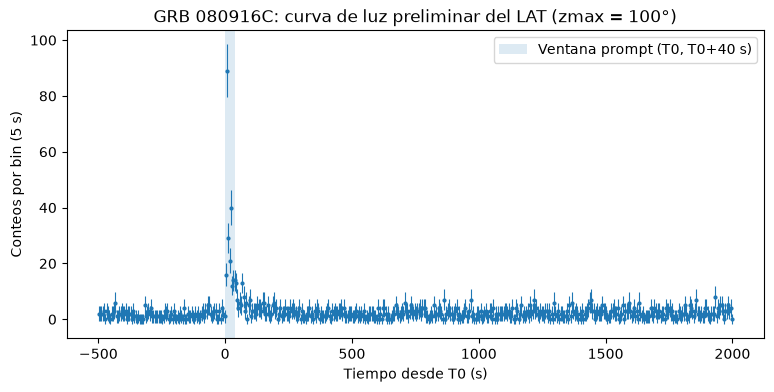

In [5]:
import matplotlib.pyplot as plt
from astropy.io import fits

lc = fits.getdata('data/lc_zmax100.fits', ext=1)  # columnas: TIME, TIMEDEL, COUNTS, ERROR

t = lc['TIME'] - float(os.environ['T0'])   # tiempo relativo al disparo
plt.figure(figsize=(9, 4))
plt.errorbar(t, lc['COUNTS'], xerr=lc['TIMEDEL']/2, yerr=lc['ERROR'], fmt='.', ms=4, lw=0.8)
plt.xlabel('Tiempo desde T0 (s)')
plt.ylabel('Conteos por bin (5 s)')
plt.title('GRB 080916C: curva de luz preliminar del LAT (zmax = 100°)')
plt.axvspan(0, 40, alpha=0.15, label='Ventana prompt (T0, T0+40 s)')
plt.legend()
plt.show()

En la curva de luz el estallido se concentra justo después de T0: una estimación razonable del
intervalo de emisión prompt en el LAT es **(T0, T0 + 40 s)**, que es la ventana sombreada y la que
usaremos de aquí en adelante (coincide con la del tutorial).

## 2. Localización del GRB

### 2a. `gtselect`: recorte a la ventana prompt

Extraemos los eventos de la ventana prompt con un cono de aceptación de 15° (para quitar fotones que no
son del estallido), **sin fijar todavía el centro** (`ra=INDEF, dec=INDEF`): la posición fina la va a dar
`gtfindsrc` en el paso siguiente.


In [6]:
%%bash
gtselect evclass=16 \
    infile=data/filtered_zmax100.fits \
    outfile=data/localize_zmax100.fits \
    ra=INDEF dec=INDEF rad=15 \
    tmin=$TPROMPT1 tmax=$TPROMPT2 \
    emin=$EMIN emax=$EMAX \
    zmax=$ZMAX

Done.


### 2b. `gtfindsrc`: posición de máxima verosimilitud

`gtfindsrc` ajusta iterativamente la posición de una fuente puntual maximizando la log-verosimilitud, y
estima el radio de error. Como la integración es de solo ~40 s, los fondos difusos e instrumentales son
despreciables: por eso **no** pasamos modelo de fuentes (`srcmdl=none`), ni mapa de exposición, ni
*livetime cube* (`expmap=none`, `expcube=none`). Partimos de la posición semilla de la circular.

- IRF de la fase prompt: `P8R3_TRANSIENT020_V3` (la que corresponde a `evclass=16`).
- Si la herramienta pregunta `Target source name`, responder con Enter (vacío): solo hay una fuente.


In [7]:
%%bash
gtfindsrc \
    evfile=data/localize_zmax100.fits \
    scfile=data/FT2.fits \
    outfile=data/GRB080916C_gtfindsrc.txt \
    irfs=P8R3_TRANSIENT020_V3 \
    expcube=none expmap=none srcmdl=none \
    coordsys=CEL ra=$RA_SEED dec=$DEC_SEED \
    optimizer=MINUIT ftol=0.01 atol=0.01
cat data/GRB080916C_gtfindsrc.txt

Target source name[cat data/GRB080916C_gtfindsrc.txt] Source 'cat data/GRB080916C_gtfindsrc.txt' not found in source model.
Enter coordinates for test source:
Best fit position: 119.9,  -56.6668
Error circle radius: 0.0663207


Con estos datos la posición de máxima verosimilitud debe quedar en **(RA, Dec) ≈ (119.861, −56.581)**,
que es la que usa el tutorial. La guardamos como la posición de referencia del resto del análisis
(si tu corrida da una posición ligeramente distinta, pon aquí la tuya).


In [8]:
import os
os.environ['RA_GRB']  = '119.9'
os.environ['DEC_GRB'] = '-56.6668'
print('Posición adoptada: RA =', os.environ['RA_GRB'], ', Dec =', os.environ['DEC_GRB'])

Posición adoptada: RA = 119.9 , Dec = -56.6668


### 2c. `gtbin` (modo `CMAP`): mapa de conteos

El GRB 080916C es tan brillante que `gtfindsrc` basta para localizarlo; en GRBs con pocos fotones conviene
además hacer un **mapa de conteos** para verlo. Lo generamos centrado en la posición ajustada:
30×30 píxeles de 0.2° (una región de 6°×6°), coordenadas celestes y proyección AIT.


In [9]:
%%bash
gtbin algorithm=CMAP \
    evfile=data/localize_zmax100.fits \
    outfile=data/GRB080916C_counts_map.fits \
    scfile=NONE \
    nxpix=30 nypix=30 binsz=0.2 \
    coordsys=CEL xref=$RA_GRB yref=$DEC_GRB axisrot=0 proj=AIT

This is gtbin version HEAD


gtbin: WARNING: No spacecraft file: EXPOSURE keyword will be set equal to ontime.


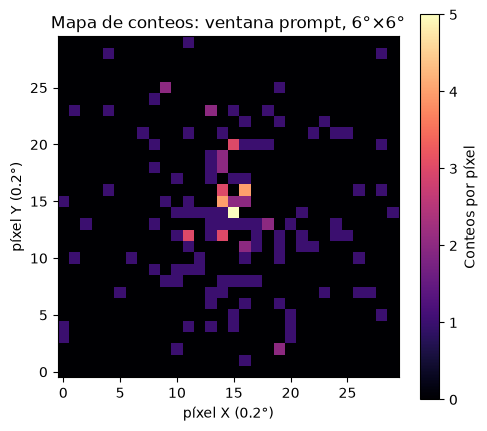

In [10]:
# El mapa puede verse con ds9 (!ds9 data/GRB080916C_counts_map.fits &) o aquí mismo:
import matplotlib.pyplot as plt
from astropy.io import fits

mapa = fits.getdata('data/GRB080916C_counts_map.fits')
plt.figure(figsize=(5.5, 5))
plt.imshow(mapa, origin='lower', cmap='magma')
plt.colorbar(label='Conteos por píxel')
plt.title('Mapa de conteos: ventana prompt, 6°×6°')
plt.xlabel('píxel X (0.2°)'); plt.ylabel('píxel Y (0.2°)')
plt.show()

### 2d. Curva de luz con la posición ajustada 

Con la posición ya refinada se rehace la curva de luz, ahora en dos paneles:
arriba los conteos por bin con una marca naranja por fotón, abajo la energía de cada fotón contra el
tiempo, coloreada por su **separación angular a la posición ajustada** del GRB. Se reutilizan la curva
de `gtbin` (`lc_zmax100.fits`) y los eventos filtrados (`filtered_zmax100.fits`): no hay que volver a
correr ninguna herramienta.


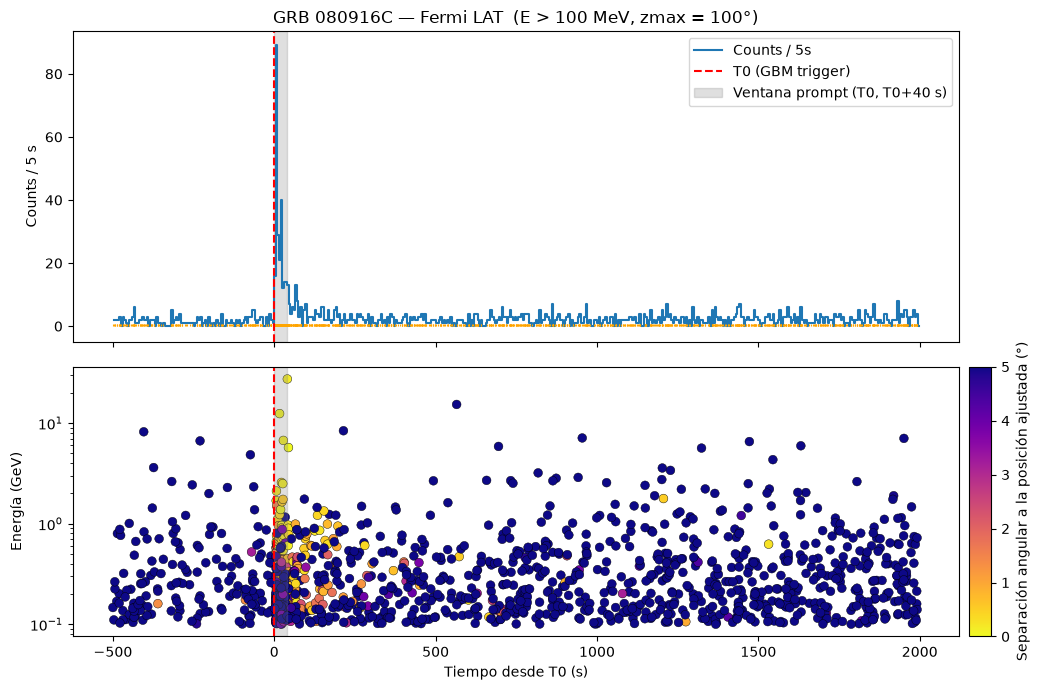

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from mpl_toolkits.axes_grid1 import make_axes_locatable
from astropy.io import fits
from astropy.coordinates import SkyCoord

import os

T0 = 243216766.614
# Posición ajustada por gtfindsrc; valores por defecto por si el kernel es nuevo:
pos_grb = SkyCoord(float(os.environ.get('RA_GRB', 119.861)),
                   float(os.environ.get('DEC_GRB', -56.581)), unit='deg')

lc = fits.getdata('data/lc_zmax100.fits', ext=1)        # TIME, TIMEDEL, COUNTS, ERROR
ev = fits.getdata('data/filtered_zmax100.fits', ext=1)  # eventos con el corte de zmax
sep = SkyCoord(ev['RA'], ev['DEC'], unit='deg').separation(pos_grb).deg
t_ev = ev['TIME'] - T0

fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(10.5, 7), sharex=True,
                               gridspec_kw={'height_ratios': [1.15, 1]})

ax1.step(lc['TIME'] - T0, lc['COUNTS'], where='mid', label='Counts / 5s')
ax1.eventplot(t_ev, lineoffsets=0.4, linelengths=0.8, colors='orange', lw=0.8)
ax1.axvline(0, color='red', ls='--', label='T0 (GBM trigger)')
ax1.axvspan(0, 40, color='gray', alpha=0.25, label='Ventana prompt (T0, T0+40 s)')
ax1.set_ylabel('Counts / 5 s')
ax1.set_title('GRB 080916C — Fermi LAT  (E > 100 MeV, zmax = 100°)')
ax1.legend()

sc = ax2.scatter(t_ev, ev['ENERGY']/1000.0, c=np.clip(sep, 0, 5), cmap='plasma_r',
                 vmin=0, vmax=5, edgecolors='k', linewidths=0.3, s=40)
ax2.axvline(0, color='red', ls='--')
ax2.axvspan(0, 40, color='gray', alpha=0.25)
ax2.set_yscale('log')
ax2.set_xlabel('Tiempo desde T0 (s)')
ax2.set_ylabel('Energía (GeV)')
# La barra de color va en un eje aparte y arriba se reserva el mismo espacio,
# para que ambos paneles tengan exactamente el mismo ancho y eje de tiempo.
cax_arriba = make_axes_locatable(ax1).append_axes('right', size='2.5%', pad=0.1)
cax_arriba.axis('off')
cax = make_axes_locatable(ax2).append_axes('right', size='2.5%', pad=0.1)
fig.colorbar(sc, cax=cax, label='Separación angular a la posición ajustada (°)')
plt.tight_layout()
plt.savefig('data/LC_080916C.png', dpi=150)
plt.show()

## 3. Archivos para el análisis de la emisión prompt

Aunque para este GRB los fondos son despreciables, seguimos el procedimiento completo (el que haría falta
para un GRB débil, como el GRB 251118A): definir un modelo con fondos difusos y calcular la exposición.

### 3a. `gtselect`: selección final de la fase prompt

Repetimos la selección de la ventana prompt, ahora **centrada en la posición ajustada**:


In [12]:
%%bash
gtselect evclass=16 \
    infile=data/filtered_zmax100.fits \
    outfile=data/prompt_select.fits \
    ra=$RA_GRB dec=$DEC_GRB rad=15 \
    tmin=$TPROMPT1 tmax=$TPROMPT2 \
    emin=$EMIN emax=$EMAX \
    zmax=$ZMAX

Done.


### 3b. Modelo de la región de interés (XML)

El modelo de la ROI tiene **tres componentes** (el tutorial lo construye con `ModelEditor`; aquí lo
escribimos directamente, que es equivalente):

1. **GRB_080916C**: fuente puntual en la posición ajustada, con espectro `PowerLaw2` (ley de potencia
   parametrizada por el flujo integral entre dos energías y el índice espectral; ambos libres).
2. **Fondo difuso galáctico** (GALPROP): la emisión de la Vía Láctea por interacción de rayos cósmicos
   con el gas interestelar, con el mapa estándar `gll_iem_v07.fits` y normalización libre.
3. **Fondo isotrópico extragaláctico**: ley de potencia de índice fijo −2.1 con prefactor libre; incluye
   también el residuo de partículas cargadas mal clasificadas.


In [13]:
import os
xml = f"""<?xml version="1.0" ?>
<source_library title="Source Library" xmlns="http://fermi.gsfc.nasa.gov/source_library">
  <source name="GRB_080916C" type="PointSource">
    <spectrum type="PowerLaw2">
      <parameter free="true" max="1000.0" min="1e-05" name="Integral" scale="1e-06" value="1.0"/>
      <parameter free="true" max="-1.0" min="-5.0" name="Index" scale="1.0" value="-2.0"/>
      <parameter free="false" max="200000.0" min="20.0" name="LowerLimit" scale="1.0" value="100.0"/>
      <parameter free="false" max="200000.0" min="20.0" name="UpperLimit" scale="1.0" value="200000.0"/>
    </spectrum>
    <spatialModel type="SkyDirFunction">
      <parameter free="false" max="360.0" min="0.0" name="RA" scale="1.0" value="{os.environ['RA_GRB']}"/>
      <parameter free="false" max="90.0" min="-90.0" name="DEC" scale="1.0" value="{os.environ['DEC_GRB']}"/>
    </spatialModel>
  </source>
  <source name="GALPROP Diffuse Source" type="DiffuseSource">
    <spectrum type="ConstantValue">
      <parameter free="true" max="10.0" min="0.0" name="Value" scale="1.0" value="1.0"/>
    </spectrum>
    <spatialModel file="$(FERMI_DIR)/refdata/fermi/galdiffuse/gll_iem_v07.fits" type="MapCubeFunction">
      <parameter free="false" max="1000.0" min="0.001" name="Normalization" scale="1.0" value="1.0"/>
    </spatialModel>
  </source>
  <source name="Extragalactic Diffuse Source" type="DiffuseSource">
    <spectrum type="PowerLaw">
      <parameter free="true" max="100.0" min="1e-05" name="Prefactor" scale="1e-07" value="1.6"/>
      <parameter free="false" max="-1.0" min="-3.5" name="Index" scale="1.0" value="-2.1"/>
      <parameter free="false" max="200.0" min="50.0" name="Scale" scale="1.0" value="100.0"/>
    </spectrum>
    <spatialModel type="ConstantValue">
      <parameter free="false" max="10.0" min="0.0" name="Value" scale="1.0" value="1.0"/>
    </spatialModel>
  </source>
</source_library>"""

with open('data/GRB080916C_model.xml', 'w') as f:
    f.write(xml)
print('Modelo escrito en data/GRB080916C_model.xml')

Modelo escrito en data/GRB080916C_model.xml


El mapa galáctico `gll_iem_v07.fits` debe estar en `$FERMI_DIR/refdata/fermi/galdiffuse/`.
La celda siguiente lo descarga **solo si no está** (pesa ~500 MB):


In [14]:
%%bash
destino="$FERMI_DIR/refdata/fermi/galdiffuse/gll_iem_v07.fits"
if [ -f "$destino" ]; then
    echo "Ya existe: $destino"
else
    wget -nc https://fermi.gsfc.nasa.gov/ssc/data/analysis/software/aux/gll_iem_v07.fits -P "$FERMI_DIR/refdata/fermi/galdiffuse/"
fi

Ya existe: /home/fabriciooos/miniconda3/envs/fermi/share/fermitools/refdata/fermi/galdiffuse/gll_iem_v07.fits


### 3c. `gtmktime` y `gtltcube`: por qué aquí NO se corren

- **`gtmktime`** depura los intervalos de buen tiempo (GTI) con la información del FT2. Con una ventana de
  solo 40 s no aplica (incluso reporta errores); se usará en la parte extendida.
- **`gtltcube`** calcula el *livetime cube* (tiempo efectivo de observación por dirección y ángulo de
  incidencia). Para integraciones menores de ~1000 s es más rápido dejar que `gtexpmap` integre
  directamente sobre el FT2, así que tampoco se corre aquí.

### 3d. `gtdiffrsp`: respuesta a las componentes difusas

Como trabajamos con la clase `TRANSIENT` hay que correr `gtdiffrsp`: para cada fotón calcula la integral
del modelo de cada componente difusa (convuelta con la PSF y el área efectiva) y la escribe en las
columnas `DIFRSP0` y `DIFRSP1` del propio archivo de eventos. Sin esto, el ajuste de verosimilitud no
puede separar la fuente puntual de los fondos. **Modifica `prompt_select.fits` en el lugar** y es un paso
pesado (por el tamaño del mapa galáctico): puede tardar varios minutos.


In [15]:
%%bash
gtdiffrsp \
    evfile=data/prompt_select.fits \
    scfile=data/FT2.fits \
    srcmdl=data/GRB080916C_model.xml \
    irfs=P8R3_TRANSIENT020_V3

adding source Extragalactic Diffuse Source
adding source GALPROP Diffuse Source


Working on...
data/prompt_select.fits......................!


### 3e. `gtexpmap`: mapa de exposición

`gtexpmap` genera el mapa de exposición que necesita el análisis de verosimilitud **unbinned** para
convertir conteos en flujos. El radio de la *source region* (25°) es mayor que el de extracción (15°):
se agrega un colchón de 10° para recoger la contribución de las colas de la PSF de fuentes justo fuera de
la región (recomendado cuando la energía mínima baja hasta 100 MeV). `expcube=none` porque no calculamos
*livetime cube* (ver 3c).


In [16]:
%%bash
gtexpmap \
    evfile=data/prompt_select.fits \
    scfile=data/FT2.fits \
    expcube=none \
    outfile=data/prompt_expmap.fits \
    irfs=P8R3_TRANSIENT020_V3 \
    srcrad=25 nlong=100 nlat=100 nenergies=20

The exposure maps generated by this tool are meant
to be used for *unbinned* likelihood analysis only.
Do not use them for binned analyses.
Half-degree pixels are a nominal choice for point-source analysis.When working on extended sources, the pixel size of the exposure map must be small enough to sample the smallest extended source present in the model.


Computing the ExposureMap (no expCube file given) 


....................!


## 4. Análisis binned con XSPEC (emisión prompt)

Para ajustar el espectro de la fase prompt en XSPEC hacen falta dos archivos: el **espectro de conteos**
(`.pha`) y la **matriz de respuesta** (`.rsp`).

### 4a. `gtbin` (modo `PHA1`): el espectro

`PHA1` produce un único espectro acumulado sobre toda la ventana del archivo de entrada, con 30 canales
logarítmicos entre 100 MeV y 300 GeV:


In [17]:
%%bash
gtbin algorithm=PHA1 \
    evfile=data/prompt_select.fits \
    outfile=data/080916C_LAT.pha \
    scfile=data/FT2.fits \
    ebinalg=LOG emin=$EMIN emax=$EMAX enumbins=30

This is gtbin version HEAD


### 4b. `gtrspgen`: la matriz de respuesta

`gtrspgen` construye, a partir de las IRF del LAT, la matriz que mapea los bins de energía del fotón
**incidente** a los canales de **salida** del `.pha`. Dos cosas importantes del tutorial:

- Usar siempre el método `PS` (*Point Source*); el método `GRB` quedó sin desarrollar y `PS` es más
  preciso, sobre todo para estallidos largos.
- Los bins de energía incidente (100 aquí) deben **sobremuestrear** los canales de salida (30): con pocos
  canales, más bins incidentes dan un cálculo más preciso del número esperado de fotones por canal.


In [18]:
%%bash
gtrspgen respalg=PS \
    specfile=data/080916C_LAT.pha \
    scfile=data/FT2.fits \
    outfile=data/080916C_LAT.rsp \
    thetacut=90 dcostheta=0.5 \
    irfs=CALDB \
    ebinalg=LOG emin=$EMIN emax=$EMAX enumbins=100

This is gtrspgen version HEAD


### 4c. Ajuste en XSPEC

Un detalle práctico antes de abrir XSPEC: `gtrspgen` graba en el encabezado del PHA
`RESPFILE = 'data/080916C_LAT.rsp'`, con la ruta relativa al cuaderno. Si XSPEC se abre desde otra
carpeta, esa ruta no resuelve, y XSPEC entra al modo «New filename», que espera **solo nombres de
archivo** y se traga como nombres cualquier comando que se escriba ahí. Para evitarlo, la celda
siguiente reescribe `RESPFILE` con el nombre a secas (`080916C_LAT.rsp`) y declara `POISSERR = T` (los
conteos son poissonianos, lo que además quita un *warning*); después XSPEC se corre **desde `data/`** y
encuentra la respuesta solo, sin comando `response`.

El modelo es `pow` (ley de potencia simple) con estadístico **C-stat** (pocos conteos), y los residuos
se grafican **normalizados por la incertidumbre** (`plot ldata delchi`). Si corres sin entorno gráfico,
cambia `cpd /xs` por `cpd /null`. Y si XSPEC llegara a preguntar `New filename`, respóndele solo con el
nombre del archivo (sin la palabra `response`).


In [19]:
# Arreglo del encabezado del PHA: respuesta con nombre a secas y errores poissonianos declarados.
from astropy.io import fits
fits.setval('data/080916C_LAT.pha', 'RESPFILE', value='080916C_LAT.rsp', ext=1)
fits.setval('data/080916C_LAT.pha', 'POISSERR', value=True, ext=1)
print("RESPFILE ->", fits.getval('data/080916C_LAT.pha', 'RESPFILE', ext=1))
print("POISSERR ->", fits.getval('data/080916C_LAT.pha', 'POISSERR', ext=1))

RESPFILE -> 080916C_LAT.rsp
POISSERR -> True


In [ ]:
%%bash
cd data
xspec <<'EOF'
query yes
data 080916C_LAT.pha
model pow
2.0
1.0
statistic cstat
cpd /xs
setplot energy
fit
plot ldata delchi
show all
exit
EOF

El resultado de este ajuste es el siguiente: 
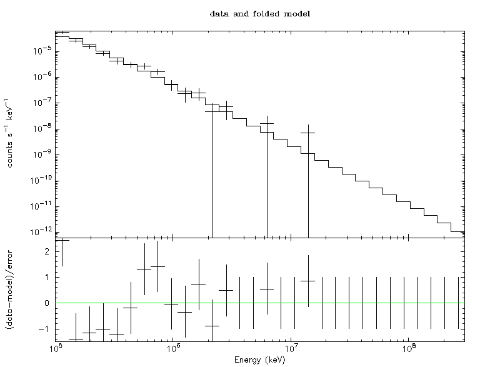

Y el flujo de xspec fue este: 

pectral Data File: 080916C_LAT.pha  Spectrum 1
Net count rate (cts/s) for Spectrum:1  5.918e+00 +/- 3.999e-01
 Assigned to Data Group 1 and Plot Group 1
  Noticed Channels:  1-30
  Telescope: GLAST Instrument: LAT  Channel Type: PI
  Exposure Time: 37 sec
 Using fit statistic: chi
 Using Response (RMF) File            080916C_LAT.rsp for Source 1

XSPEC>response 080916C_LAT.rsp
Response successfully loaded.
XSPEC>model pow

Input parameter value, delta, min, bot, top, and max values for ...
              1       0.01(      0.01)         -3         -2          9         10
1:powerlaw:PhoIndex>
              1       0.01(      0.01)          0          0      1e+20      1e+24
2:powerlaw:norm>

Fit statistic  : Chi-Squared              1.478369e+11     using 30 bins.

***Warning: Chi-square may not be valid due to bins with zero variance
            in spectrum number: 1

Test statistic : Chi-Squared              1.478369e+11     using 30 bins.

***Warning: Chi-square may not be valid due to bins with zero variance
            in spectrum number(s): 1 

 Null hypothesis probability of 0.000000e+00 with 28 degrees of freedom
 Current data and model not fit yet.

========================================================================
Model powerlaw<1> Source No.: 1   Active/On
Model Model Component  Parameter  Unit     Value
 par  comp
   1    1   powerlaw   PhoIndex            1.00000      +/-  0.0          
   2    1   powerlaw   norm                1.00000      +/-  0.0          
________________________________________________________________________

XSPEC>statistic cstat
Default fit statistic is set to: C-Statistic
   This will apply to all current and newly loaded spectra.

Fit statistic  : C-Statistic              4.948842e+06     using 30 bins.

Test statistic : Chi-Squared              1.478369e+11     using 30 bins.

***Warning: Chi-square may not be valid due to bins with zero variance
            in spectrum number(s): 1 

 Null hypothesis probability of 0.000000e+00 with 28 degrees of freedom
 Current data and model not fit yet.
XSPEC>cpd /xs
XSPEC>setplot energy
XSPEC>fit
                                   Parameters
C-Statistic  |beta|/N    Lvl    1:PhoIndex        2:norm
LM is using analytic gradients (better numerical accuracy on tabulated models).
Parameter uncertainties may differ from previous FD-based fits; on expensive-likelihood fits (large
response convolutions) per-iteration cost may be higher.  Set "xset DISABLE_ANALYTIC_GRAD yes" to
revert to finite differences.
628.589      353.341      -2       1.10574   0.000194643
546.794      321097       -2       1.12266   0.000333027
496.747      141959       -2       1.15561   0.000588330
453.659      72298.9      -2       1.19081    0.00103115
414.235      38776.8      -2       1.22541    0.00177840
378.294      21065.2      -2       1.25931    0.00301559
345.667      11593.9      -2       1.29245    0.00502453
316.155      6472         -2       1.32477    0.00822252
289.54       3668.97      -2       1.35624     0.0132124
265.594      2115.91      -2       1.38680     0.0208437
Number of trials exceeded: continue fitting? 
244.083      1244.73      -2       1.41643     0.0322856
224.778      750.338      -2       1.44512     0.0491097
207.461      466.978      -2       1.47285     0.0733829
191.924      303.287      -2       1.49961      0.107767
177.976      207.979      -2       1.52542      0.155620
165.441      151.644      -2       1.55029      0.221108
154.163      117.207      -2       1.57422      0.309300
144          94.8884      -2       1.59726      0.426277
134.826      79.2965      -2       1.61941      0.579216
126.53       67.5723      -2       1.64072      0.776479
Number of trials exceeded: continue fitting? 
119.014      58.2259      -2       1.66121       1.02768
112.191      50.4703      -2       1.68091       1.34375
105.986      43.8701      -2       1.69986       1.73698
100.332      38.1664      -2       1.71808       2.22102
95.1707      33.1917      -2       1.73562       2.81093
90.4499      28.8281      -2       1.75250       3.52316
86.1247      24.9865      -2       1.76875       4.37552
82.1551      21.5961      -2       1.78439       5.38713
78.5056      18.5983      -2       1.79947       6.57841
75.1452      15.9441      -2       1.81400       7.97095
Number of trials exceeded: continue fitting? 
72.0461      13.5912      -2       1.82801       9.58748
69.1838      11.5034      -2       1.84153       11.4517
66.5365      9.64937      -2       1.85457       13.5884
64.0847      8.00164      -2       1.86717       16.0229
61.811       6.53637      -2       1.87933       18.7814
59.6999      5.23271      -2       1.89108       21.8906
57.7374      4.07239      -2       1.90244       25.3775
55.9109      3.03941      -2       1.91342       29.2696
54.2093      2.11974      -2       1.92405       33.5943
52.6223      1.3012       -2       1.93433       38.3790
Number of trials exceeded: continue fitting? 
51.1407      0.574008     -2       1.94428       43.6512
49.7562      0.102975     -2       1.95392       49.4377
48.4612      0.659647     -2       1.96326       55.7653
47.249       1.17143      -2       1.97231       62.6600
46.1133      1.62667      -2       1.98108       70.1470
45.0484      2.03063      -2       1.98959       78.2510
44.0491      2.38843      -2       1.99784       86.9955
43.1106      2.70472      -2       2.00584       96.4032
42.2288      2.98366      -2       2.01361       106.495
41.3995      3.22899      -2       2.02115       117.293
Number of trials exceeded: continue fitting? 
40.6191      3.44404      -2       2.02848       128.813
39.8844      3.63179      -2       2.03559       141.076
39.1921      3.79493      -2       2.04250       154.095
38.5396      3.93587      -2       2.04922       167.887
37.9241      4.05676      -2       2.05575       182.464
37.3432      4.15956      -2       2.06210       197.838
36.7947      4.246        -2       2.06827       214.019
36.2766      4.31767      -2       2.07427       231.015
35.7869      4.376        -2       2.08011       248.833
35.3239      4.42228      -2       2.08580       267.477
Number of trials exceeded: continue fitting? 
34.8858      4.45765      -2       2.09133       286.952
34.4713      4.48319      -2       2.09671       307.260
34.0788      4.49985      -2       2.10196       328.399
33.707       4.50848      -2       2.10706       350.370
33.3548      4.50988      -2       2.11203       373.169
33.0209      4.50476      -2       2.11688       396.791
32.7043      4.49376      -2       2.12160       421.232
32.6202      4.47748      -3       2.16103       629.569
30.4584      121.753      -3       2.18603       884.587
29.0138      90.8906      -3       2.20768       1185.28
Number of trials exceeded: continue fitting? 
28.084       65.191       -3       2.22632       1521.00
27.4862      45.7918      -3       2.24226       1878.12
27.0986      31.6689      -3       2.25579       2242.55
26.8444      21.6328      -3       2.26722       2601.58
26.6758      14.6273      -3       2.27683       2945.11
26.5627      9.80086      -3       2.28489       3265.94
26.4862      6.50758      -3       2.29164       3559.67
26.4341      4.27695      -3       2.29728       3824.22
26.3985      2.77551      -3       2.30199       4059.32
26.3914      1.77101      -4       2.31735       4844.61
==============================
 Variances and Principal Axes
                 1        2  
 2.9369E-05|  1.0000  -0.0000  
 1.7485E+07|  0.0000   1.0000  
------------------------------

========================
  Covariance Matrix
        1           2   
   6.825e-03   3.447e+02
   3.447e+02   1.748e+07
------------------------

========================================================================
Model powerlaw<1> Source No.: 1   Active/On
Model Model Component  Parameter  Unit     Value
 par  comp
   1    1   powerlaw   PhoIndex            2.31735      +/-  8.26123E-02  
   2    1   powerlaw   norm                4844.61      +/-  4181.50      
________________________________________________________________________


Fit statistic  : C-Statistic                   26.39     using 30 bins.

Test statistic : Chi-Squared                   19.38     using 30 bins.

***Warning: Chi-square may not be valid due to bins with zero variance
            in spectrum number(s): 1 

 Null hypothesis probability of 8.86e-01 with 28 degrees of freedom
XSPEC>
XSPEC>plot ldata delchi
XSPEC>show all

XSPEC version: 13.0.1

Thu Nov 12 06:47:43 2026
 Auto-saving is done after every command.
 Fit statistic in use: C-Statistic
 Minimization technique: Levenberg-Marquardt
    Convergence criterion = 0.01
    Parameter fit deltas: 0.01 * parValue
Using chain rule to calculate statistic derivatives (faster method).
 Querying enabled.
 Prefit-renorming enabled.
 Solar abundance table: angr
 Photoionization Cross-Section Table:
    vern:  Verner, Ferland, Korista, and Yakovlev 1996
 Cosmology in use: H0 = 70 q0 = 0 Lambda0 = 0.73
 Model data directory: /home/fabriciooos/heasoft/x86_64-pc-linux-gnu-libc2.42/../spectral/manager/../modelData/
 Plot settings:
   Showing of individual additive components is OFF.
   Showing of background spectra is OFF.
   Effective area normalization is OFF.
   Current unit settings:
      Energy     = keV
      Wavelength = angstrom, with Y-Axis displayed per Hz
   X-Axis data display mode: Energy
   Spectra plots will be shifted to source frame by redshift value z: 0
   Device: /xs
   Plotting of line IDs is OFF.
   Splashpage is ON.
   xlog for data plots is ON.
   ylog for data plots is OFF.

   Default plot rebin settings for all plot groups:
   Min. Signif.   Max. # Bins   Error Type
        0.00000             1         quad

 Responses read: 
   080916C_LAT.rsp associated with spectrum 1 source 1
      energies: 100 channels: 30
 Distinct RMF files: 
     /home/fabriciooos/Descargas/informe-final-correcciones/GRB080916C/data/080916C_LAT.rsp

1 file 1 spectrum 
Spectrum 1  Spectral Data File: 080916C_LAT.pha
Net count rate (cts/s) for Spectrum:1  5.918e+00 +/- 3.999e-01
 Assigned to Data Group 1 and Plot Group 1
  Noticed Channels:  1-30
  Telescope: GLAST Instrument: LAT  Channel Type: PI
  Exposure Time: 37 sec
 Using fit statistic: cstat
 Using Response (RMF) File            080916C_LAT.rsp for Source 1

 Spectral data counts: 219
 Model predicted rate: 5.81876


Current model list:

========================================================================
Model powerlaw<1> Source No.: 1   Active/On
Model Model Component  Parameter  Unit     Value
 par  comp
   1    1   powerlaw   PhoIndex            2.31735      +/-  8.26123E-02  
   2    1   powerlaw   norm                4844.61      +/-  4181.50      
________________________________________________________________________

   Using energies from responses.

Fit statistic  : C-Statistic                   26.39     using 30 bins.

Test statistic : Chi-Squared                   19.38     using 30 bins.

***Warning: Chi-square may not be valid due to bins with zero variance
            in spectrum number(s): 1 

 Null hypothesis probability of 8.86e-01 with 28 degrees of freedom

Bayes is off

XSPEC>



Del ajuste interesan el índice fotónico (`PhoIndex`, esperable ≈ 2.2 para este GRB), su
incertidumbre y el valor de C-stat frente a los grados de libertad. Para ver el cociente datos/modelo en
lugar de los residuos, repetir con `plot ldata ratio`.

## 5. Análisis unbinned con gtlike (emisión extendida)

Muchos GRBs del LAT muestran emisión de alta energía que persiste después de la fase prompt. Para
buscarla se analiza la ventana **T0+40 a T0+400 s** con el método de máxima verosimilitud *unbinned*
(no agrupa los eventos en bins de energía: apropiado cuando hay pocos fotones).

### 5a. `gtselect`: selección de la ventana extendida

Ahora con `evclass=128` (clase `SOURCE`): más estricta en la discriminación del fondo, adecuada para
intervalos largos. Se parte otra vez del `FT1.fits` crudo:


In [18]:
%%bash
gtselect evclass=128 \
    infile=data/FT1.fits \
    outfile=data/extended_select.fits \
    ra=$RA_GRB dec=$DEC_GRB rad=15 \
    tmin=$TEXT1 tmax=$TEXT2 \
    emin=$EMIN emax=$EMAX \
    zmax=$ZMAX

Done.


### 5b. `gtmktime`: depuración de los intervalos de buen tiempo

Con una ventana más larga sí corresponde correr `gtmktime`, que cruza los eventos con el FT2 y excluye los
periodos de mala calidad usando el filtro estándar recomendado por el Cicerone,
`(DATA_QUAL>0)&&(LAT_CONFIG==1)`. Con `roicut=yes` también recorta los tiempos en que la ROI sale del
campo de visión. (Si se analizara clase *transient*, el filtro de calidad sería igualmente `DATA_QUAL>0`.)


In [21]:
%%bash
gtmktime \
    scfile=data/FT2.fits \
    filter="(DATA_QUAL>0)&&(LAT_CONFIG==1)" \
    roicut=yes \
    evfile=data/extended_select.fits \
    outfile=data/extended_mktime.fits

### 5c. `gtdiffrsp`: respuesta difusa (ahora con la IRF de SOURCE)

Mismo paso que en 3d, pero sobre la selección extendida y con `P8R3_SOURCE_V3`, la IRF que corresponde a
`evclass=128`. También es un paso lento.


In [22]:
%%bash
gtdiffrsp \
    evfile=data/extended_mktime.fits \
    scfile=data/FT2.fits \
    srcmdl=data/GRB080916C_model.xml \
    irfs=P8R3_SOURCE_V3

adding source Extragalactic Diffuse Source
adding source GALPROP Diffuse Source


Working on...
data/extended_mktime.fits.........................!


### 5d. `gtltcube`: livetime cube

Con 360 s de datos ya conviene precalcular el tiempo efectivo de observación en función de la dirección
en el cielo y del ángulo de incidencia. `dcostheta=0.025` es el paso en cos(θ) y `binsz=0.5` el tamaño de
píxel en grados.


In [23]:
%%bash
gtltcube \
    evfile=data/extended_mktime.fits \
    scfile=data/FT2.fits \
    outfile=data/extended_ltcube.fits \
    dcostheta=0.025 binsz=0.5

Working on file data/FT2.fits
..............!


### 5e. `gtexpmap`: mapa de exposición de la ventana extendida

Igual que en 3e, pero esta vez **sí** pasamos el *livetime cube* recién calculado:


In [24]:
%%bash
gtexpmap \
    evfile=data/extended_mktime.fits \
    scfile=data/FT2.fits \
    expcube=data/extended_ltcube.fits \
    outfile=data/extended_expmap.fits \
    irfs=P8R3_SOURCE_V3 \
    srcrad=25 nlong=100 nlat=100 nenergies=20

The exposure maps generated by this tool are meant
to be used for *unbinned* likelihood analysis only.
Do not use them for binned analyses.
Half-degree pixels are a nominal choice for point-source analysis.When working on extended sources, the pixel size of the exposure map must be small enough to sample the smallest extended source present in the model.


Computing the ExposureMap using data/extended_ltcube.fits


....................!


### 5f. `gtlike`: ajuste de máxima verosimilitud

Con todos los insumos listos (eventos depurados, *livetime cube*, mapa de exposición y modelo XML),
`gtlike` ajusta simultáneamente los parámetros libres de las tres componentes del modelo maximizando la
verosimilitud, con el método `UNBINNED` y el optimizador `MINUIT`. `results=...` guarda los resultados
numéricos.

> *Nota:* la gráfica interactiva de `gtlike` (`plot=yes`) ya no está disponible en las
> versiones recientes de Fermitools, así que se usa `plot=no`. No importa: `gtlike` deja de todas formas
> el archivo `counts_spectra.fits` con los conteos observados y los de cada componente del modelo, y el
> espectro se grafica con Python en la celda de la sección 5g.


In [25]:
%%bash
gtlike plot=no results=data/results.dat \
    statistic=UNBINNED \
    scfile=data/FT2.fits \
    evfile=data/extended_mktime.fits \
    expmap=data/extended_expmap.fits \
    expcube=data/extended_ltcube.fits \
    srcmdl=data/GRB080916C_model.xml \
    irfs=P8R3_SOURCE_V3 \
    optimizer=MINUIT
echo '================ results.dat ================'
cat data/results.dat

100  539309
108.423  597911
117.556  659659
127.458  723129
138.194  788216
149.835  850438
162.456  911651
176.14  968886
190.976  1.02493e+06
207.063  1.07157e+06
224.504  1.1175e+06
243.415  1.16063e+06
263.918  1.20314e+06
286.149  1.24605e+06
310.252  1.28877e+06
336.385  1.33138e+06
364.72  1.37572e+06
395.441  1.4203e+06
428.75  1.46468e+06
464.864  1.50717e+06
504.021  1.5463e+06
546.476  1.58132e+06
592.507  1.6128e+06
642.416  1.6489e+06
696.528  1.68648e+06
755.198  1.72412e+06
818.81  1.76394e+06
887.781  1.81305e+06
962.561  1.86624e+06
1043.64  1.92511e+06
1131.55  1.96595e+06
1226.86  1.99658e+06
1330.2  2.00996e+06
1442.25  2.02009e+06
1563.73  2.02579e+06
1695.45  2.03764e+06
1838.26  2.06384e+06
1993.1  2.07819e+06
2160.99  2.08164e+06
2343.01  2.09108e+06
2540.37  2.10259e+06
2754.35  2.09889e+06
2986.36  2.09593e+06
3237.91  2.09922e+06
3510.65  2.09043e+06
3806.36  2.06291e+06
4126.98  2.03925e+06
4474.6  2.01796e+06
4851.51  2.0283e+06
5260.17  2.04375e+06
5703.24

...!


Flux: 0.00109213 +/- 0.000217214 photons/cm^2/s

GRB_080916C:
Integral: 62.1811 +/- 8.06963
Index: -2.01672 +/- 0.107907
LowerLimit: 100
UpperLimit: 200000
Npred: 70.2277
ROI distance: 0.0884419
TS value: 455.143
Flux: 6.22254e-05 +/- 8.06868e-06 photons/cm^2/s


Total number of observed counts: 99
Total number of model events: 98.9986

-log(Likelihood): 610.8253714

Elapsed CPU time: 58.244668


================ results.dat ================
{'Extragalactic Diffuse Source': {'Prefactor': '1.00563e-05 +/- 0.000465097',
'Index': '-2.1',
'Scale': '100',
'Npred': '2.06078e-05',
'Flux': '1.14941e-09 +/- 5.31249e-08',
},
'GALPROP Diffuse Source': {'Value': '2.09651 +/- 0.417036',
'Npred': '28.7709',
'Flux': '0.00109213 +/- 0.000217214',
},
'GRB_080916C': {'Integral': '62.1811 +/- 8.06963',
'Index': '-2.01672 +/- 0.107907',
'LowerLimit': '100',
'UpperLimit': '200000',
'Npred': '70.2277',
'ROI distance': '0.0884419',
'TS value': '455.143',
'Flux': '6.22254e-05 +/- 8.06868e-06',
},
}


### 5g. Espectro de conteos y componentes del modelo (Python)

`gtlike` escribió `counts_spectra.fits` (en la carpeta del cuaderno) con, por bin de energía: los
conteos observados (`ObsCounts`) y los conteos que el modelo atribuye a cada componente. Con eso se
construye la figura del espectro: **negro = suma del modelo, rojo = GRB, verde = difuso galáctico
(GALPROP), azul = difuso extragaláctico**, los datos con sus barras de error poissonianas, y un panel de
residuos (conteos − modelo)/modelo.


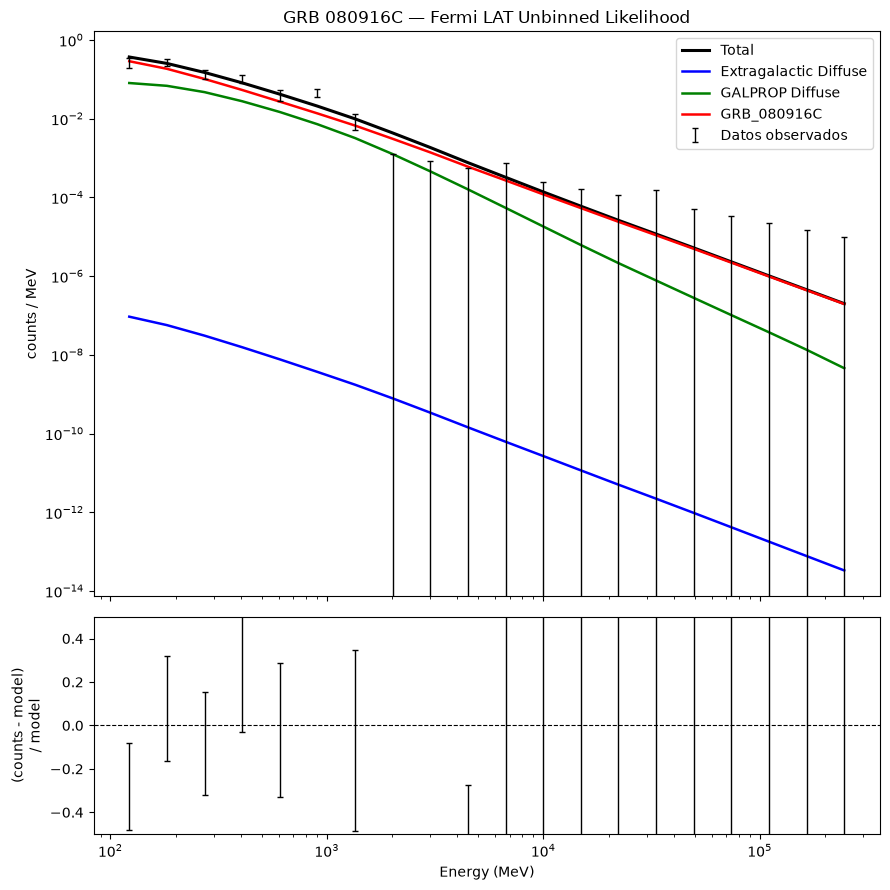

Conteos observados: 99.0 | predichos por el modelo: 99.02
  Extragalactic Diffuse Source: Npred = 0.00
  GALPROP Diffuse Source: Npred = 28.80
  GRB_080916C: Npred = 70.23


In [26]:
import os
import numpy as np
import matplotlib.pyplot as plt
from astropy.io import fits

ruta = 'counts_spectra.fits' if os.path.exists('counts_spectra.fits') else 'data/counts_spectra.fits'
with fits.open(ruta) as f:
    esp = f['COUNTS_SPECTRA'].data
    eb = f['EBOUNDS'].data

E = np.sqrt(eb['E_MIN'] * eb['E_MAX'])          # centro geométrico del bin (MeV)
dE = eb['E_MAX'] - eb['E_MIN']                  # ancho del bin (MeV)
obs = esp['ObsCounts'].astype(float)
componentes = [n for n in esp.columns.names if n != 'ObsCounts']
total = np.sum([esp[n] for n in componentes], axis=0)

colores = {}
for n in componentes:
    colores[n] = ('red' if 'GRB' in n else 'green' if 'GALPROP' in n.upper() else 'blue')

fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(9, 9), sharex=True,
                               gridspec_kw={'height_ratios': [2.6, 1]})

ax1.plot(E, total/dE, 'k-', lw=2.2, label='Total')
for n in componentes:
    ax1.plot(E, esp[n]/dE, color=colores[n], lw=1.8, label=n.replace(' Source', ''))
yerr = np.sqrt(np.maximum(obs, 1.0))
ax1.errorbar(E, obs/dE, yerr=yerr/dE, fmt='none', ecolor='k', elinewidth=1,
             capsize=2, label='Datos observados')
ax1.set_xscale('log'); ax1.set_yscale('log')
ax1.set_ylabel('counts / MeV')
ax1.set_title('GRB 080916C — Fermi LAT Unbinned Likelihood')
ax1.legend()

con = total > 0
ax2.errorbar(E[con], (obs[con]-total[con])/total[con], yerr=yerr[con]/total[con],
             fmt='none', ecolor='k', elinewidth=1, capsize=2)
ax2.axhline(0, color='k', ls='--', lw=0.8)
ax2.set_xscale('log')
ax2.set_ylim(-0.5, 0.5)
ax2.set_xlabel('Energy (MeV)')
ax2.set_ylabel('(counts - model)\n/ model')
plt.tight_layout()
plt.savefig('data/Espectro_080916C.png', dpi=150)
plt.show()

print('Conteos observados:', obs.sum(), '| predichos por el modelo: %.2f' % total.sum())
for n in componentes:
    print(f'  {n}: Npred = {esp[n].sum():.2f}')

De la salida de `gtlike` hay que revisar, para la fuente `GRB_080916C`:

- el **índice espectral** (`Index`) y el **flujo integral** (`Integral`, en el rango 100 MeV–200 GeV del
  modelo), con sus incertidumbres;
- el **Test Statistic (TS)** = −2 ln(L0/L1), donde L0 y L1 son las verosimilitudes sin y con la fuente:
  TS ≳ 25 equivale aproximadamente a una detección de 5σ;
- `Npred`, el número de fotones que el modelo atribuye al GRB, comparado con los conteos observados;
- y que las normalizaciones de los dos fondos difusos hayan quedado en valores razonables (la galáctica
  cerca de 1).

## Resumen de archivos generados

| Archivo | Herramienta | Para qué sirve |
|---|---|---|
| `data/FT1.fits`, `data/FT2.fits` | descarga | eventos y nave, crudos |
| `data/filtered_zmax100.fits` | `gtselect` | base filtrada (zmax, clase transient) |
| `data/lc_zmax100.fits` | `gtbin LC` | curva de luz preliminar |
| `data/localize_zmax100.fits` | `gtselect` | ventana prompt para localizar |
| `data/GRB080916C_gtfindsrc.txt` | `gtfindsrc` | posición ajustada del GRB |
| `data/GRB080916C_counts_map.fits` | `gtbin CMAP` | mapa de conteos |
| `data/prompt_select.fits` | `gtselect` (+`gtdiffrsp`) | eventos prompt con respuesta difusa |
| `data/GRB080916C_model.xml` | a mano | modelo de la ROI (3 componentes) |
| `data/prompt_expmap.fits` | `gtexpmap` | exposición de la ventana prompt |
| `data/080916C_LAT.pha`, `.rsp` | `gtbin PHA1`, `gtrspgen` | espectro y respuesta para XSPEC |
| `data/extended_select.fits` | `gtselect` | ventana extendida, clase source |
| `data/extended_mktime.fits` | `gtmktime` (+`gtdiffrsp`) | eventos depurados por GTI |
| `data/extended_ltcube.fits` | `gtltcube` | livetime cube |
| `data/extended_expmap.fits` | `gtexpmap` | exposición de la ventana extendida |
| `data/results.dat` | `gtlike` | resultados del ajuste unbinned |

Referencia: [LAT Gamma-Ray Burst Analysis](https://fermi.gsfc.nasa.gov/ssc/data/analysis/scitools/lat_grb_analysis.html) (FSSC).
